# 18 · Auditoría de horizontes y prueba de estacionalidad semanal

**Objetivo:** verificar si el menor RMSE observado en torno a 7 y 14 días sobrevive a una evaluación de **horizonte exacto**, con idénticos orígenes para todos los horizontes y modelos.

**Alcance:** SARIMAX semanal, SARIMAX sin semana, persistencia y persistencia estacional. Esta es una **auditoría previa** a la comparación definitiva de cuatro arquitecturas. **No reentrena las redes neuronales.**

**Regla:** cada origen `t` produce 15 pronósticos para `t+1`…`t+15`; después se revela **solo** el precio del día siguiente y se avanza un origen. No se actualiza con datos de `t+h` antes de emitir su pronóstico.

**Escenarios de covariables:** `oracle` utiliza valores futuros realizados (análisis condicionado, **no** operativo); `congeladas` mantiene las últimas covariables observadas en el origen (sensibilidad, **no** pronóstico de covariables). Ambos se etiquetan por separado.


In [1]:
from pathlib import Path
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf
warnings.filterwarnings('default')

def raiz():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p/'data'/'processed'/'dataset_consolidado.parquet').exists():
            return p
    raise FileNotFoundError('No se encontró data/processed/dataset_consolidado.parquet')
ROOT=raiz(); OUT=ROOT/'reports'/'auditoria_horizontes_1_a_15'; OUT.mkdir(parents=True,exist_ok=True)
TEST_START=pd.Timestamp('2025-08-01'); TEST_END=pd.Timestamp('2026-07-31')
HS=list(range(1,16)); EXOG=['gen_termica','ONI','aportes_energia_gwh']; TARGET='precio_bolsa'
# True = evaluar también el escenario con covariables congeladas. Aumenta tiempo, no el entrenamiento.
INCLUIR_CONGELADAS=True
print('Proyecto:',ROOT,'\nReportes:',OUT)


Proyecto: /Users/maguverm/Documents/tesis-bolsa 
Reportes: /Users/maguverm/Documents/tesis-bolsa/reports/auditoria_horizontes_1_a_15


In [2]:
df=pd.read_parquet(ROOT/'data'/'processed'/'dataset_consolidado.parquet').sort_index()
df.index=pd.to_datetime(df.index)
assert df.index.is_unique, 'Fechas duplicadas'
assert all(c in df.columns for c in [TARGET,*EXOG]), 'Faltan columnas'
assert not df[[TARGET,*EXOG]].isna().any().any(), 'Hay datos faltantes: revisar antes de evaluar'
train=df.loc[df.index<TEST_START].copy()
test=df.loc[(df.index>=TEST_START)&(df.index<=TEST_END)].copy()
assert len(test)>max(HS)
assert (test.index.to_series().diff().dropna()==pd.Timedelta(days=1)).all(), 'Test no es diario consecutivo'
assert train.index.max()==test.index.min()-pd.Timedelta(days=1), 'Train/test no son contiguos'
# Mismos orígenes para todos los horizontes: último origen = fecha final - 15 días
N=len(test)-max(HS)+1
origins=pd.DatetimeIndex([train.index[-1], *test.index[:N-1]])
assert len(origins)==N
print('Train:',len(train),'Test:',len(test),'Orígenes comunes:',N)
print('Primer origen:',origins[0].date(),'Último origen:',origins[-1].date())


Train: 4595 Test: 365 Orígenes comunes: 351
Primer origen: 2025-07-31 Último origen: 2026-07-16


/var/folders/vz/dknzsyq13c55x4nb5c75hmn40000gn/T/ipykernel_1636/2231924692.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert (test.index.to_series().diff().dropna()==pd.Timedelta(days=1)).all(), 'Test no es diario consecutivo'
/var/folders/vz/dknzsyq13c55x4nb5c75hmn40000gn/T/ipykernel_1636/2231924692.py:10: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert train.index.max()==test.index.min()-pd.Timedelta(days=1), 'Train/test no son contiguos'


## 1. Estimar ambos SARIMAX **solo con train**

Misma parte no estacional `(2,0,2)` y mismas covariables. Registrar convergencia: una comparación con un ajuste no convergente es provisional.

In [3]:
FITS={}
for nombre,seasonal in [('SARIMAX semanal',(1,0,1,7)),('SARIMAX sin semana',(0,0,0,0))]:
    t0=time.time()
    mod=SARIMAX(train[TARGET],exog=train[EXOG],order=(2,0,2),
               seasonal_order=seasonal,enforce_stationarity=False,enforce_invertibility=False)
    fit=mod.fit(disp=False,maxiter=300)
    FITS[nombre]=fit
    converged=bool(fit.mle_retvals.get('converged',False))
    print(nombre,'| convergencia:',converged,'| AIC:',round(fit.aic,2),'| segundos:',round(time.time()-t0,1))
    if not converged:
        print('⚠️ ADVERTENCIA: parámetros sin convergencia; interpretar este contraste como exploratorio.')


/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:174: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  endog.shape = (endog.shape[0], 1)  # this will be C-contiguous
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be

SARIMAX semanal | convergencia: False | AIC: 52392.66 | segundos: 1.5
⚠️ ADVERTENCIA: parámetros sin convergencia; interpretar este contraste como exploratorio.
SARIMAX sin semana | convergencia: False | AIC: 51112.43 | segundos: 0.3
⚠️ ADVERTENCIA: parámetros sin convergencia; interpretar este contraste como exploratorio.


/opt/anaconda3/envs/tesis-bolsa/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 2. Pronóstico rolling-origin de horizonte **exacto**

En cada origen se pronostican los 15 días siguientes y se guardan todos los pasos **con su horizonte real**. La actualización incorpora una sola observación posterior al pronóstico, nunca el bloque completo.

In [4]:
def evaluar_sarimax_rolling(fit, nombre, escenario='oracle'):
    estado=fit; filas=[]
    t0=time.time()
    for k,origen in enumerate(origins):
        futuro=test.iloc[k:k+max(HS)]
        assert len(futuro)==max(HS)
        if escenario=='oracle':
            xf=futuro[EXOG]
        elif escenario=='congeladas':
            # Al origen 0, última fila de train; luego, último día revelado.
            xlast=(train.iloc[-1] if k==0 else test.iloc[k-1])[EXOG].to_numpy(dtype=float)
            xf=pd.DataFrame(np.tile(xlast,(max(HS),1)),index=futuro.index,columns=EXOG)
        else: raise ValueError(escenario)
        fc=estado.get_forecast(steps=max(HS),exog=xf)
        mu=np.asarray(fc.predicted_mean,dtype=float)
        se=np.asarray(fc.se_mean,dtype=float)
        for h in HS:
            fecha=futuro.index[h-1]
            filas.append({'modelo':nombre,'escenario':escenario,'origen':origen,
                'fecha':fecha,'h':h,'real':float(futuro[TARGET].iloc[h-1]),
                'pred':mu[h-1],'std':se[h-1],
                'p10':mu[h-1]+norm.ppf(.1)*se[h-1],
                'p90':mu[h-1]+norm.ppf(.9)*se[h-1]})
        # Actualizar el estado solo con la observación siguiente. En el último origen no hace falta.
        if k<len(origins)-1:
            obs=test.iloc[k:k+1]
            estado=estado.append(obs[TARGET],exog=obs[EXOG],refit=False)
        if (k+1)%100==0: print(nombre,escenario,f'{k+1}/{len(origins)} orígenes')
    print('Terminado:',nombre,escenario,'en',round(time.time()-t0,1),'segundos')
    return pd.DataFrame(filas)

partes=[]
for nombre,fit in FITS.items():
    partes.append(evaluar_sarimax_rolling(fit,nombre,'oracle'))
    if INCLUIR_CONGELADAS:
        partes.append(evaluar_sarimax_rolling(fit,nombre,'congeladas'))
pred_sarimax=pd.concat(partes,ignore_index=True)
assert len(pred_sarimax)==len(origins)*15*len(partes)
pred_sarimax.to_parquet(OUT/'predicciones_sarimax_horizonte_exacto.parquet',index=False)
print('Predicciones SARIMAX guardadas:',len(pred_sarimax))


SARIMAX semanal oracle 100/351 orígenes
SARIMAX semanal oracle 200/351 orígenes
SARIMAX semanal oracle 300/351 orígenes
Terminado: SARIMAX semanal oracle en 8.5 segundos
SARIMAX semanal congeladas 100/351 orígenes
SARIMAX semanal congeladas 200/351 orígenes
SARIMAX semanal congeladas 300/351 orígenes
Terminado: SARIMAX semanal congeladas en 8.3 segundos
SARIMAX sin semana oracle 100/351 orígenes
SARIMAX sin semana oracle 200/351 orígenes
SARIMAX sin semana oracle 300/351 orígenes
Terminado: SARIMAX sin semana oracle en 3.0 segundos
SARIMAX sin semana congeladas 100/351 orígenes
SARIMAX sin semana congeladas 200/351 orígenes
SARIMAX sin semana congeladas 300/351 orígenes
Terminado: SARIMAX sin semana congeladas en 3.1 segundos
Predicciones SARIMAX guardadas: 21060


## 3. Benchmarks con **idénticos orígenes**

Persistencia ordinaria: precio del origen. Persistencia semanal: último precio disponible del **mismo día de semana que el objetivo**; para `h>7` no se utiliza información futura.

In [5]:
historico=pd.concat([train[TARGET],test[TARGET]]).sort_index()
filas=[]
for k,origen in enumerate(origins):
    visto=historico.loc[:origen]
    p0=float(visto.iloc[-1])
    for h in HS:
        fecha=test.index[k+h-1]
        y=float(test[TARGET].iloc[k+h-1])
        mismo_dia=visto.loc[visto.index.dayofweek==fecha.dayofweek]
        p7=float(mismo_dia.iloc[-1]) if len(mismo_dia) else p0
        for modelo,p in [('Persistencia',p0),('Persistencia semanal',p7)]:
            filas.append({'modelo':modelo,'escenario':'benchmark','origen':origen,
                          'fecha':fecha,'h':h,'real':y,'pred':p})
pred_base=pd.DataFrame(filas)
pred_base.to_parquet(OUT/'predicciones_benchmarks_horizonte_exacto.parquet',index=False)


## 4. Validación automática de alineación y cálculo de métricas

In [7]:
# ============================================================
# 4. VALIDACIÓN Y MÉTRICAS POR HORIZONTE EXACTO
# ============================================================

pred = pd.concat(
    [pred_sarimax, pred_base],
    ignore_index=True
)

# Verificaciones de integridad
assert not pred.empty, "No hay predicciones para evaluar."

assert not pred.duplicated(
    ["modelo", "escenario", "origen", "h"]
).any(), "Hay predicciones duplicadas."

assert (
    pred["fecha"] - pred["origen"]
).dt.days.eq(pred["h"]).all(), (
    "Las fechas no corresponden al horizonte t+h."
)

assert pred.groupby(
    ["modelo", "escenario", "h"]
).size().eq(len(origins)).all(), (
    "Los modelos tienen diferente número de orígenes."
)

real_por_caso = pred.groupby(
    ["origen", "h"]
)["real"].agg(["min", "max"])

assert np.allclose(
    real_por_caso["min"],
    real_por_caso["max"]
), "Los modelos no comparten los mismos valores reales."

# Calcular métricas explícitamente por grupo
# Evitamos depender del comportamiento de groupby.apply()

filas_metricas = []

for (modelo, escenario, h), g in pred.groupby(
    ["modelo", "escenario", "h"],
    sort=True
):

    y = g["real"].to_numpy(dtype=float)
    p = g["pred"].to_numpy(dtype=float)

    error = y - p

    fila = {
        "modelo": modelo,
        "escenario": escenario,
        "h": int(h),
        "N": len(g),
        "MAE": float(np.mean(np.abs(error))),
        "RMSE": float(np.sqrt(np.mean(error ** 2))),
        "Sesgo": float(np.mean(p - y)),
        "Cobertura80": np.nan,
        "Ancho80": np.nan,
        "IntervalScore80": np.nan,
    }

    if (
        "p10" in g.columns
        and "p90" in g.columns
        and g["p10"].notna().all()
        and g["p90"].notna().all()
    ):

        lo = g["p10"].to_numpy(dtype=float)
        hi = g["p90"].to_numpy(dtype=float)

        fila["Cobertura80"] = float(
            100 * np.mean((y >= lo) & (y <= hi))
        )

        fila["Ancho80"] = float(
            np.mean(hi - lo)
        )

        fila["IntervalScore80"] = float(
            np.mean(
                (hi - lo)
                + 10 * (lo - y) * (y < lo)
                + 10 * (y - hi) * (y > hi)
            )
        )

    filas_metricas.append(fila)

tabla = pd.DataFrame(filas_metricas)

assert not tabla.empty, "La tabla de métricas está vacía."
assert "RMSE" in tabla.columns, "No se calculó la columna RMSE."
assert tabla["RMSE"].notna().all(), "Hay valores RMSE faltantes."

# Guardar resultados
tabla.to_csv(
    OUT / "metricas_horizonte_exacto.csv",
    index=False
)

tabla.to_parquet(
    OUT / "metricas_horizonte_exacto.parquet",
    index=False
)

# Tabla comparativa
comparacion = tabla.pivot_table(
    index="h",
    columns=["modelo", "escenario"],
    values="RMSE"
)

print("Modelos evaluados:")
print(tabla.groupby(["modelo", "escenario"]).size())

print("\nRMSE POR HORIZONTE EXACTO")
display(comparacion.round(2))

print("\nValidación completada correctamente.")


Modelos evaluados:
modelo                escenario 
Persistencia          benchmark     15
Persistencia semanal  benchmark     15
SARIMAX semanal       congeladas    15
                      oracle        15
SARIMAX sin semana    congeladas    15
                      oracle        15
dtype: int64

RMSE POR HORIZONTE EXACTO


modelo    Persistencia Persistencia semanal SARIMAX semanal          \
escenario    benchmark            benchmark      congeladas  oracle   
h                                                                     
1                55.57               120.07           58.43   54.01   
2                79.32               120.04           80.30   70.77   
3                93.51               120.05           94.82   82.19   
4               104.34               120.06          106.79   90.77   
5               112.30               120.11          116.13   97.19   
6               115.20               120.08          121.91  103.43   
7               120.27               120.27          128.00  110.27   
8               130.93               161.77          140.53  119.25   
9               141.69               161.80          152.42  124.43   
10              150.35               162.23          163.75  128.96   
11              155.70               162.54          171.43  133.34   
12              160.23               162.74          177.26  137.95   
13              161.39               162.91          180.84  142.58   
14              163.06               163.06          183.63  145.76   
15              167.72               169.74          187.56  148.08   

modelo    SARIMAX sin semana          
escenario         congeladas  oracle  
h                                     
1                      57.21   48.04  
2                      80.71   62.30  
3                      94.10   72.12  
4                     104.53   79.50  
5                     112.89   85.12  
6                     116.96   91.70  
7                     124.15   98.66  
8                     135.71  104.60  
9                     145.98  108.09  
10                    154.25  110.92  
11                    160.00  114.17  
12                    163.77  117.76  
13                    165.59  121.27  
14                    169.52  125.26  
15                    175.50  129.10


Validación completada correctamente.


## 5. ¿Persisten los valles de los días 7 y 14?

Un mínimo local no demuestra causalidad estacional. Se contrasta también el beneficio del SARIMAX semanal respecto a su versión sin semana y respecto al benchmark semanal.

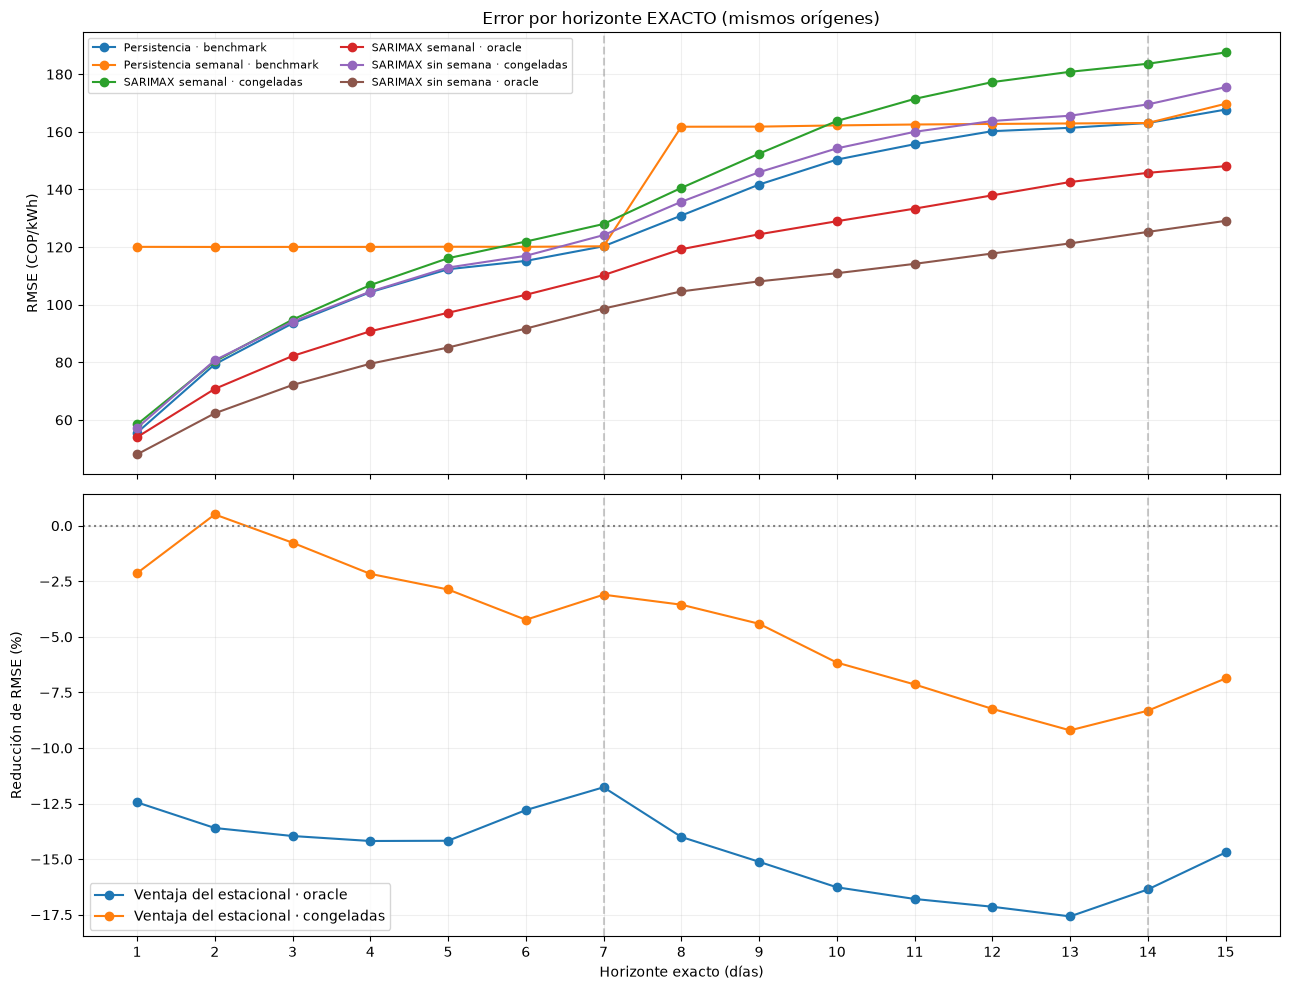

In [8]:
fig,axs=plt.subplots(2,1,figsize=(13,10),sharex=True)
for (m,e),g in tabla.groupby(['modelo','escenario']):
    axs[0].plot(g.h,g.RMSE,marker='o',label=f'{m} · {e}')
axs[0].set_ylabel('RMSE (COP/kWh)');axs[0].set_title('Error por horizonte EXACTO (mismos orígenes)')
axs[0].legend(fontsize=8,ncol=2);axs[0].grid(alpha=.2)
for escenario in ['oracle']+(['congeladas'] if INCLUIR_CONGELADAS else []):
    z=tabla[tabla.escenario==escenario].pivot(index='h',columns='modelo',values='RMSE')
    ventaja=100*(z['SARIMAX sin semana']-z['SARIMAX semanal'])/z['SARIMAX sin semana']
    axs[1].plot(ventaja.index,ventaja,marker='o',label=f'Ventaja del estacional · {escenario}')
axs[1].axhline(0,color='gray',ls=':');axs[1].set_ylabel('Reducción de RMSE (%)')
axs[1].set_xlabel('Horizonte exacto (días)');axs[1].legend();axs[1].grid(alpha=.2)
for ax in axs:
    ax.set_xticks(HS)
    for h in [7,14]:ax.axvline(h,color='gray',ls='--',alpha=.4)
fig.tight_layout();fig.savefig(OUT/'contraste_horizonte_exacto.png',dpi=180);plt.show()


## 6. Evidencia complementaria de periodicidad semanal

La ACF del precio y de sus diferencias puede mostrar dependencia a rezagos 7 y 14, pero una autocorrelación no prueba que la componente SARIMAX sea causalmente responsable de las mejoras.

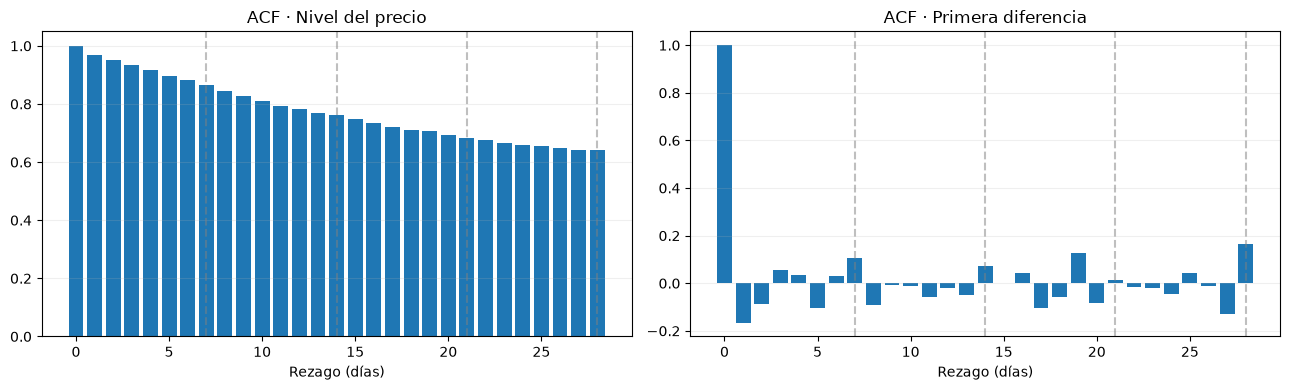

In [9]:
serie=train[TARGET].astype(float)
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax,x,titulo in [(axs[0],serie,'Nivel del precio'),(axs[1],serie.diff().dropna(),'Primera diferencia')]:
    vals=acf(x,nlags=28,fft=True)
    ax.bar(range(len(vals)),vals)
    for h in [7,14,21,28]:ax.axvline(h,color='gray',ls='--',alpha=.5)
    ax.set_title('ACF · '+titulo);ax.set_xlabel('Rezago (días)');ax.grid(axis='y',alpha=.2)
fig.tight_layout();fig.savefig(OUT/'acf_semanal.png',dpi=180);plt.show()


## 7. Informe de auditoría

**Interpretación permitida:** comparar curvas de error de horizonte exacto, mismas fechas de origen y mismos valores reales, y contrastar especificaciones SARIMAX.

**Limitaciones que permanecen:** `oracle` conoce covariables futuras reales; `congeladas` es una sensibilidad simplificada, no un modelo exógeno operativo. La convergencia debe verificarse. Las predicciones anteriores de LSTM/TFT basadas en bloques no son comparables con estas curvas y deberán regenerarse con origen diario. La GRU ya produce salidas por horizonte, pero se debe auditar el conjunto de orígenes y el acceso a features antes de incluirla. No se recalibraron intervalos usando test.

**Siguiente etapa:** construir la comparación definitiva de cuatro modelos usando estos mismos orígenes y una política coherente de covariables futuras.

In [10]:
print('ARCHIVOS GENERADOS:')
for f in sorted(OUT.iterdir()):
    print(f.name)
print('\nEstado de convergencia:')
for name,fit in FITS.items():
    print(name,fit.mle_retvals.get('converged',False))


ARCHIVOS GENERADOS:
acf_semanal.png
contraste_horizonte_exacto.png
metricas_horizonte_exacto.csv
metricas_horizonte_exacto.parquet
predicciones_benchmarks_horizonte_exacto.parquet
predicciones_sarimax_horizonte_exacto.parquet

Estado de convergencia:
SARIMAX semanal False
SARIMAX sin semana False
